# Analysis of Covid-19 papers

**Master:** Physics of Data \
**Course:** Management and Analysis of Physics Dataset - Module B (MAPD-B) \
**Professor:** Jacopo Pazzini \
**Students:**  Andres David Rojas Lozano, Gabriela Landinez Rangel, Elena Niero,  Polina Gridiaeva 

# Task 2. Which are the worst and best-represented countries/institutes in the research?

### Spark set up

In [1]:
from pyspark.sql import SparkSession


# Define the number of executors and number of cores for each one
executor_instances =3 
executor_cores = 8

# Build the spark session
spark = SparkSession.builder \
    .master("spark://master:7077") \
    .appName("COVID-19 task 2") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-common:3.3.4,org.apache.hadoop:hadoop-aws:3.3.4") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")\
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")\
    .config('spark.hadoop.fs.s3a.aws.credentials.provider', 'org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')\
    .config("spark.hadoop.fs.s3a.access.key", "ACCESS_KEY") \
    .config("spark.hadoop.fs.s3a.secret.key", "SECRET_KEY") \
    .config('spark.hadoop.fs.s3a.endpoint', 'https://cloud-areapd.pd.infn.it:5210')\
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.metadatastore.impl", "org.apache.hadoop.fs.s3a.s3guard.NullMetadataStore") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled","false") \
    .config("com.amazonaws.sdk.disableCertChecking","true") \
    .config("spark.executor.instances", executor_instances) \
    .config("spark.executor.cores", executor_cores) \
    .config("spark.cores.max", executor_instances * executor_cores) \
    .config("spark.executor.memory", "2g") \
    .getOrCreate()

# test with a `take` of 3 elements from one file
#spark.read.format("text").load('s3a://mapd-minidt-stream/data_000000.txt').take(3)
# extend the test to count all entries out of 10 files
#spark.read.format("text").load('s3a://mapd-minidt-stream/data_00001*.txt').count()

:: loading settings :: url = jar:file:/mnt/vol2/env/jup_env/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.apache.hadoop#hadoop-common added as a dependency
org.apache.hadoop#hadoop-aws added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-5cbf0c5d-904e-47b4-93c6-5ba73037d85e;1.0
	confs: [default]
	found org.apache.hadoop#hadoop-common;3.3.4 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-protobuf_3_7;1.1.1 in central
	found org.apache.hadoop#hadoop-annotations;3.3.4 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-guava;1.1.1 in central
	found com.google.guava#guava;27.0-jre in central
	found com.google.guava#failureaccess;1.0 in central
	found com.google.guava#listenablefuture;9999.0-empty-to-avoid-conflict-with-guava in central
	found com.google.cod

In [2]:
sc = spark.sparkContext
sc
#spark.stop()

<SparkContext master=spark://master:7077 appName=Second Point Affiliation>

### Import all the other libraries


In [3]:
import json
import re
import socket
from collections import Counter
import nltk
import re
import socket
from collections import Counter
import os
from pathlib import Path
import pyspark.sql.functions as sf
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /home/ubuntu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

A verification and count over the available files in the directories, and the after count with the clean list.

In [4]:
%%time
base_dir = Path("/mnt/vol2/.cache/kagglehub/datasets/allen-institute-for-ai/CORD-19-research-challenge/versions/50/document_parses/")
all_paths = list(base_dir.rglob("*.json"))
print(f"Total JSON files found in disk: {len(all_paths)}")

df_pandas=pd.read_csv('/mnt/vol2/.cache/kagglehub/directory.csv')
valid_files = set(df_pandas['path'])
#all_path = [path for path in all_paths if path.name in valid_files]
all_paths = [str(path) for path in all_paths if path.name in valid_files]
print(f"Total JSON files to process (filtered): {len(all_paths)}")

Total JSON files found in disk: 183369
Total JSON files to process (filtered): 128782
CPU times: user 1.84 s, sys: 248 ms, total: 2.08 s
Wall time: 2.08 s


The definition of the function for the feature extraction related to the authors of each paper. Here we defined an iterative loop over all the files, searching for the information necessary to complete the task, such as **Paper id, Institution, Laboratory, Settlement and Country** , then those are saved in a dictionary.

In [6]:

def author_ext(path):
    try:
        with open(path) as f:
            doc =json.load(f)
    except Exception:
        return []

    affiliation=[]
    p_id=doc.get("paper_id",None)
    meta= doc.get("metadata",{})
    auth= meta.get("authors",[])
    for author in auth:
        aff=author.get("affiliation",{})
        if aff:
            location = aff.get("location", {})
            auth_data={
                "paper_id":p_id,
                "ins":aff.get("institution",None),
                "lab":aff.get("laboratory",None),
                "city":location.get("settlement",None),
                "country":location.get("country",None)
                
            }
            affiliation.append(auth_data)
    return affiliation


Now we can use `parallelize()` to take this python collection (index blocks) and turn it into an RDD (Resilient Distributed Dataset), so that each partition can be processed independently and in parallel across
the available executors.



In [7]:
%%time
start=time.time()
paths_rdd = sc.parallelize(all_paths, numSlices=120)

# Flatmap allows us to threat every author as an individual  row
author_rdd = paths_rdd.flatMap(author_ext)
df_spark = spark.createDataFrame(author_rdd)

end=time.time()
print(end-start)


2.909548044204712
CPU times: user 68 ms, sys: 21.5 ms, total: 89.5 ms
Wall time: 2.91 s


### Data preprocessing and cleaning

An extra process of cleaning is needed after the initial preprocessing done in **Task 0**.

In order to have an accessible dataset, we started implementing pyspark SQL functions for the processing of the dataset, with a cleaning of the regular expressions for any white spaces (`\s`) and the No-Break Space (`\u00a0`) present in the papers.
The text will be normalized in uppercase for the posterior process of grouping.
The trim function will delete the spaces at the beginning of the word or at the end of the string variable.

Then, a specific cleaning for the institution task, due to the high volume of **null** values in the specific field of `institution`, but the presence of a `laboratory`, we decided to copy the latter as the institution of affiliation, leading then to 0 null values after the operation.

We performed the same operation for the countries, bringing the city to the country column, but the result of this was a total of more than **6,200** values in the country field. Therefore, instead of applying that approach to the problem, we decided to fill it with an "UNKNOWN" string.



In [8]:

start=time.time()
#Here we are deleting the regular expressions, the spaces before, double space or special characters
df_spark_norm = df_spark \
    .withColumn("ins", sf.trim(sf.regexp_replace(sf.upper(sf.col("ins")), r"[\s\u00a0]+", " "))) \
    .withColumn("country", sf.trim(sf.regexp_replace(sf.upper(sf.col("country")), r"[\s\u00a0]+", " "))) \
    .withColumn("city", sf.trim(sf.regexp_replace(sf.upper(sf.col("city")), r"[\s\u00a0]+", " "))) \
    .withColumn("lab", sf.trim(sf.regexp_replace(sf.upper(sf.col("lab")), r"[\s\u00a0]+", " "))) 

# Then, for the null values in institution, we are going to copy the laboratory of affiliation 
df_spark_norm = df_spark_norm.withColumn("ins",sf.when((sf.col("ins").isNull() | (sf.col("ins") == "")) &
                                                       (sf.col("lab").isNotNull() & (sf.col("lab") != "")),
                                                       sf.col("lab")).otherwise(sf.col("ins")))


# Second change, instead of puting the city because of the +6k different values in countries, we will just fill it as No specified
df_spark_norm = df_spark_norm.withColumn("country",sf.when(sf.col("country").isNull() | (sf.col("country") == ""), sf.lit("UNKNOWN")).otherwise(sf.col("country")))
end=time.time()
print(end-start)

0.22799944877624512


In [9]:
df_spark_norm.show(10)

[Stage 1:>                                                          (0 + 1) / 1]

+--------------------+---------+--------------------+--------------------+--------------------+
|                city|  country|                 ins|                 lab|            paper_id|
+--------------------+---------+--------------------+--------------------+--------------------+
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|CHANGCHUN, CHANGC...|    CHINA|CHINESE ACADEMY O...|STATE KEY LABORAT...|3703093f16e819c54...|
|           SINGAPORE|SINGAPORE|NATIONAL


## Institution representation by author affiliation 

It is interesting that even after the regex cleaning, we still have some extra spaces at the very beginning of the name; this can be due to other special characters.

First, we compute the dataframe by grouping by the institution values, counting them, and saving the result in cache. This is done for the posterior sorting due to the immutability property of dataframes in Spark and to not recompute the dataframes.


In [31]:
start=time.time()
inst_count = df_spark_norm.groupBy("ins").count().cache()
print('Top 20 most represented')
inst_count.sort("count", ascending=False).show(20)
print('Top 20 least represented')
inst_count.sort("count",ascending=True).show(20)
inst_count.unpersist()
end= time.time()
print(end-start)

Top 20 most represented


[Stage 505:======================================================>(95 + 1) / 96]

+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|CHINESE ACADEMY O...| 3084|
|HUAZHONG UNIVERSI...| 2759|
|UNIVERSITY OF CAL...| 2585|
|NATIONAL INSTITUT...| 1705|
|THE UNIVERSITY OF...| 1690|
|HARVARD MEDICAL S...| 1617|
|UNIVERSITY OF OXFORD| 1446|
|    FUDAN UNIVERSITY| 1344|
|UNIVERSITY OF WAS...| 1339|
|UNIVERSITY OF TOR...| 1154|
| ZHEJIANG UNIVERSITY| 1153|
|UNIVERSITY OF PEN...| 1147|
|    WUHAN UNIVERSITY| 1075|
|IMPERIAL COLLEGE ...| 1075|
|CHINESE ACADEMY O...| 1001|
|         MAYO CLINIC|  891|
| STANFORD UNIVERSITY|  887|
|UNIVERSITY COLLEG...|  817|
|CAPITAL MEDICAL U...|  812|
|SUN YAT-SEN UNIVE...|  806|
+--------------------+-----+
only showing top 20 rows
Top 20 least represented
+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|UNIVERSITY OF ARK...|    1|
| BIOSYNTH CARBOSYNTH|    1|
|THE XINSHAO PEOPL...|    1|
|                 MHH|    1|
|UNIVERSITÄTS-KIND...|    1|
|SERVICIO VIROLOGÍ...|

In [33]:
start=time.time()
inst_count_nulls = df_spark_norm.filter(sf.col("ins").isNull() | (sf.col("ins") == "")).count()
end=time.time()
print('Total null values for institution: ',inst_count_nulls)
print(end-start)

[Stage 512:======================================================>(95 + 1) / 96]

Total null values for institution:  0
14.199561834335327


## Country representation by author affiliation


We start counting the unique values for the country values.

In [34]:

distinct_countries = [
    row["country"] for row in df_spark_norm.select("country").distinct().collect()
    if row["country"]
]

print('Total different values for countries',len(distinct_countries))  

[Stage 515:======================================================>(95 + 1) / 96]

Total different values for countries 2921




Due to the high number of unique values in the dataset, we decided to create a dictionary to unify the country names that were written in different ways. With the assistance of the LLM tool Claude Sonnet 5, we focused this approach on the top 100 countries, which represent 94.67% of the total paper-country relationships, reducing the variability in the data while preserving the information.

In [13]:
# This list was totally created by AI for the mapping of the names in the dataset , for the noise or dispersion reduction

manual_map = {
    "USA": "UNITED STATES",
    "US": "UNITED STATES",
    "U.S.A": "UNITED STATES",
    "U.S.A.": "UNITED STATES",
    "UNITED STATES OF AMERICA": "UNITED STATES",
    "UNITED STATES": "UNITED STATES",
    "CALIFORNIA": "UNITED STATES",
    "PENNSYLVANIA": "UNITED STATES",
    "NEW JERSEY": "UNITED STATES",
    "CHINA": "CHINA",
    "PR CHINA": "CHINA",
    "P.R. CHINA": "CHINA",
    "P. R. CHINA": "CHINA",
    "P.R.CHINA": "CHINA",
    "PEOPLE'S REPUBLIC OF CHINA": "CHINA",
    "THE PEOPLE'S REPUBLIC OF CHINA": "CHINA",
    "CHINA.": "CHINA",
    "CHINA·GROUP": "CHINA",
    "CHINA · GROUP": "CHINA",
    "REPUBLIC OF CHINA": "CHINA",
    "YUNNAN CHINA": "CHINA",  
    "UK": "UNITED KINGDOM",
    "U.K": "UNITED KINGDOM",
    "U.K.": "UNITED KINGDOM",
    "UNITED KINGDOM": "UNITED KINGDOM",
    "ENGLAND": "UNITED KINGDOM",
    "SCOTLAND": "UNITED KINGDOM",
    "UK)": "UNITED KINGDOM",
    "UK.": "UNITED KINGDOM",
    "KOREA": "SOUTH KOREA",        
    "SOUTH KOREA": "SOUTH KOREA",
    "REPUBLIC OF KOREA": "SOUTH KOREA",
    "REPUBLIC OF SINGAPORE": "SINGAPORE",
    "TAIWAN": "TAIWAN",
    "TAIWAN, ROC": "TAIWAN",
    "ROC": "TAIWAN",
    "TAIWAN, R.O.C": "TAIWAN",
    "THE NETHERLANDS": "NETHERLANDS",
    "NETHERLANDS": "NETHERLANDS",
    "THE NETHERLANDS.": "NETHERLANDS",
    "DEUTSCHLAND": "GERMANY",
    "FEDERAL REPUBLIC OF GERMANY": "GERMANY",
    "ESPAÑA": "SPAIN",
    "MÉXICO": "MEXICO",
    "BRASIL": "BRAZIL",
    "BRASIL.": "BRAZIL",
    "ITALIA": "ITALY",
    "ITALY.": "ITALY",
    "ÖSTERREICH": "AUSTRIA",
    "SCHWEIZ": "SWITZERLAND",
    "SWITZERLAND.": "SWITZERLAND",
    "RUSSIA": "RUSSIA",
    "RUSSIAN FEDERATION": "RUSSIA",
    "SAUDI ARABIA": "SAUDI ARABIA",
    "KINGDOM OF SAUDI ARABIA": "SAUDI ARABIA",
    "UAE": "UNITED ARAB EMIRATES",
    "UNITED ARAB EMIRATES": "UNITED ARAB EMIRATES",
    "INDIA.": "INDIA",
    "CANADA.": "CANADA",
    "CANADA;": "CANADA",
    "SPAIN.": "SPAIN",
    "UNIVERSITY": "UNKNOWN",
    "THE": "UNKNOWN",
}

Another cleaning process is necesary for the country field, we implemented a modular tokenization and mapping pipeline using PySpark SQL array functions. First, we split the original string by commas into a raw token array, followed by a transformation using the `clean_token` function to normalize each element. Then, we applied the previously created dictionary mapping inside a lambda function, utilizing `sf.coalesce` to replace the variants with their unified names while keeping unmatched values intact.

After that, we filtered the array to eliminate any remaining nulls, empty strings, or "UNKNOWN" placeholders, keeping only distinct valid tokens. Based on the size of this final array, we defined the final `country_norm` column: if an entry contains more than one distinct country, it is labeled as "MULTICOUNTRY"; if it contains exactly one, we extract that specific country; otherwise, it defaults to "UNKNOWN". Finally, all intermediate columns are dropped to maintain a clean dataset.

In [35]:
start=time.time()
def clean_token(col):
    return sf.trim(
        sf.regexp_replace(
            sf.trim(sf.regexp_replace(col, r"^[\.\;\(\)\[\]\s]+", "")),
            r"[\.\;\(\)\[\]\s0-9]+$", ""
        )
    )

mapping_expr = sf.create_map([sf.lit(x) for pair in manual_map.items() for x in pair])

df_spark_norm = df_spark_norm \
    .withColumn("country_tokens_raw", sf.split(sf.col("country"), ",")) \
    .withColumn("country_tokens_clean", sf.transform(sf.col("country_tokens_raw"), clean_token)) \
    .withColumn("country_tokens_mapped", sf.transform(
        sf.col("country_tokens_clean"),
        lambda x: sf.coalesce(mapping_expr[x], x)
    )) \
    .withColumn("country_tokens_final", sf.array_distinct(
        sf.filter(
            sf.col("country_tokens_mapped"),
            lambda x: (x.isNotNull()) & (x != "") & (x != "UNKNOWN")
        )
    )) \
    .withColumn(
        "country_norm",
        sf.when(sf.size(sf.col("country_tokens_final")) > 1, sf.lit("MULTICOUNTRY"))
          .when(sf.size(sf.col("country_tokens_final")) == 1, sf.col("country_tokens_final")[0])
          .otherwise(sf.lit("UNKNOWN"))
    ) \
    .drop("country_tokens_raw", "country_tokens_clean", "country_tokens_mapped", "country_tokens_final")

end= time.time()
print(end-start)

0.10276222229003906


Finally, as in the previous task, the calculation of the table with the information related to the country of the authors.

We arbitrarily decided to filter for counts greater than 15 to exclude misspelled values that were not captured in the previous cleaning process. It is important to note that even after the cleaning process, we still find different variants of the names for the most represented countries, as well as institution names that do not directly correspond to a country name.

In [36]:
start=time.time()
country_count = df_spark_norm.groupBy("country_norm").count().filter(sf.col("count")>15).cache() 
print('Top 20 most represented')
country_count.sort("count", ascending=False).show(20)
print('Top 20 least represented')
country_count.sort("count",ascending=True).show(20)
end=time.time()
country_count.unpersist() # To free the cache of the variable 
print(end-start)

Top 20 most represented


[Stage 518:======================================================>(95 + 1) / 96]

+--------------+-----+
|  country_norm|count|
+--------------+-----+
|       UNKNOWN|60682|
| UNITED STATES|52620|
|         CHINA|52588|
|         ITALY|19722|
|UNITED KINGDOM|17307|
|        FRANCE|11407|
|       GERMANY|10931|
|         SPAIN| 8639|
|        CANADA| 8442|
|         JAPAN| 7656|
|     AUSTRALIA| 6794|
|         INDIA| 6510|
|        BRAZIL| 5689|
|   SOUTH KOREA| 5328|
|   NETHERLANDS| 5260|
|        TAIWAN| 4391|
|  MULTICOUNTRY| 3698|
|   SWITZERLAND| 3621|
|          IRAN| 3053|
|       BELGIUM| 2852|
+--------------+-----+
only showing top 20 rows
Top 20 least represented
+--------------------+-----+
|        country_norm|count|
+--------------------+-----+
|               MALTA|   16|
|           GUATEMALA|   16|
|              OREGON|   16|
|             CHINA；|   16|
|      BEIJING，CHINA|   16|
|                FHRS|   17|
|             BELARUS|   17|
|THE UNITED STATES...|   17|
|PEOPLE'S REPUBLIC...|   17|
|            10 CHINA|   17|
|CHINA EUROPEAN RA...| 

In [37]:
counts = df_spark_norm.groupBy("country_norm").count().orderBy(sf.desc("count"))

total = df_spark_norm.count()
top_100 = counts.limit(100).agg(sf.sum("count")).collect()[0][0]

print(f"Top 100 valores covers {top_100/total*100:.2f}% of the rows")

[Stage 528:======================================================>(95 + 1) / 96]

Top 100 valores covers 98.71% of the rows


## Iterations
Once the process baseline was established, we proceeded to iterate over the pipeline using different configurations for the number of partitions in the `parallelize` method. We tested multiple values relative to the total number of available cores ($x$), specifically using $[1/3x, 2/3x, x, 2x, 4x, 8x]$. This benchmark was repeated across different cluster configurations of executors and cores, keeping the total core count constant at 24:

* 3 executors with 8 cores each
* 6 executors with 4 cores each
* 12 executors with 2 cores each

To ensure statistical reliability, we measured the average execution time across multiple runs ($n=5$) for each specific configuration, allowing for a subsequent analysis and comparison between the runs.

In [21]:
slices_values = [4,8,12,24,48, 96] # x = n_cores => partition_values=[1/3x, 2/3x, x, 2x, 4x] 
n_repeats = 5
n=4
results = []

In [23]:

results = []

for n in slices_values:
    
    # This is a shuffle distribution of the slices
    spark.conf.set("spark.sql.shuffle.partitions", str(n))
   
    for run in range(1, n_repeats+1):
        start = time.time()
        
        paths_rdd = sc.parallelize(all_paths, numSlices=n)

        # Flatmap allows us to treat every author as an individual row
        author_rdd = paths_rdd.flatMap(author_ext)
        df_spark = spark.createDataFrame(author_rdd)

        df_spark_norm = df_spark \
            .withColumn("ins", sf.trim(sf.regexp_replace(sf.upper(sf.col("ins")), r"[\s\u00a0]+", " "))) \
            .withColumn("country", sf.trim(sf.regexp_replace(sf.upper(sf.col("country")), r"[\s\u00a0]+", " "))) \
            .withColumn("city", sf.trim(sf.regexp_replace(sf.upper(sf.col("city")), r"[\s\u00a0]+", " "))) \
            .withColumn("lab", sf.trim(sf.regexp_replace(sf.upper(sf.col("lab")), r"[\s\u00a0]+", " "))) 

        # Then, for the null values in institution, we are going to copy the laboratory of affiliation 
        df_spark_norm = df_spark_norm.withColumn("ins", sf.when((sf.col("ins").isNull() | (sf.col("ins") == "")) &
                                                               (sf.col("lab").isNotNull() & (sf.col("lab") != "")),
                                                               sf.col("lab")).otherwise(sf.col("ins")))

        # Now adding the UNKNOWN value

        df_spark_norm = df_spark_norm.withColumn("country",sf.when(sf.col("country").isNull() | (sf.col("country") == ""),
                                                                   sf.lit("UNKNOWN")).otherwise(sf.col("country")))
        
        


        # Here we will see the different time of the paralelization

        # Institution affiliation

        inst_count = df_spark_norm.groupBy("ins").count().cache()
        print('Top 20 most represented Institution')
        inst_count.sort("count", ascending=False).show(20)
        print('Top 20 least represented Institution')
        inst_count.sort("count",ascending=True).show(20)
        inst_count.unpersist()

        
        # COUNTRY REPRESENTATION PROCESS :

        # The specific cleaning process

        mapping_expr = sf.create_map([sf.lit(x) for pair in manual_map.items() for x in pair])
        
        df_spark_norm = df_spark_norm \
            .withColumn("country_tokens_raw", sf.split(sf.col("country"), ",")) \
            .withColumn("country_tokens_clean", sf.transform(sf.col("country_tokens_raw"), clean_token)) \
            .withColumn("country_tokens_mapped", sf.transform(
                sf.col("country_tokens_clean"),
                lambda x: sf.coalesce(mapping_expr[x], x)
            )) \
            .withColumn("country_tokens_final", sf.array_distinct(
                sf.filter(
                    sf.col("country_tokens_mapped"),
                    lambda x: (x.isNotNull()) & (x != "") & (x != "UNKNOWN")
                )
            )) \
            .withColumn(
                "country_norm",
                sf.when(sf.size(sf.col("country_tokens_final")) > 1, sf.lit("MULTICOUNTRY"))
                  .when(sf.size(sf.col("country_tokens_final")) == 1, sf.col("country_tokens_final")[0])
                  .otherwise(sf.lit("UNKNOWN"))
            ) \
            .drop("country_tokens_raw", "country_tokens_clean", "country_tokens_mapped", "country_tokens_final")
        
        # THE TOP 20 PRINTING
                
        country_count = df_spark_norm.groupBy("country_norm").count().filter(sf.col("count")>15).cache()
        print('Top 20 most represented countries')
        country_count.sort("count", ascending=False).show(20)
        print('Top 20 least represented countries')
        country_count.sort("count",ascending=True).show(20)
        country_count.unpersist() # To free the cache of the variable 

        #END OF CODE
        end = time.time()
        execution_time = end - start
        
        print(f"Slices: {n} | Run: {run} | Time: {execution_time:.2f} s")
        

        results.append({
            "num_partitions": n,
            "rep": run,
            "time_sec": execution_time,
            "num_executors": executor_instances,
            "cores_per_executor":executor_cores 
        })



26/07/12 12:46:04 WARN TaskSetManager: Stage 48 contains a task of very large size (5329 KiB). The maximum recommended task size is 1000 KiB.


Top 20 most represented Institution


26/07/12 12:46:05 WARN TaskSetManager: Stage 49 contains a task of very large size (5329 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|CHINESE ACADEMY O...| 3084|
|HUAZHONG UNIVERSI...| 2759|
|UNIVERSITY OF CAL...| 2585|
|NATIONAL INSTITUT...| 1705|
|THE UNIVERSITY OF...| 1690|
|HARVARD MEDICAL S...| 1617|
|UNIVERSITY OF OXFORD| 1446|
|    FUDAN UNIVERSITY| 1344|
|UNIVERSITY OF WAS...| 1339|
|UNIVERSITY OF TOR...| 1154|
| ZHEJIANG UNIVERSITY| 1153|
|UNIVERSITY OF PEN...| 1147|
|IMPERIAL COLLEGE ...| 1075|
|    WUHAN UNIVERSITY| 1075|
|CHINESE ACADEMY O...| 1001|
|         MAYO CLINIC|  891|
| STANFORD UNIVERSITY|  887|
|UNIVERSITY COLLEG...|  817|
|CAPITAL MEDICAL U...|  812|
|SUN YAT-SEN UNIVE...|  806|
+--------------------+-----+
only showing top 20 rows
Top 20 least represented Institution
+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|UNIVERSITY HOSPIT...|    1|
|IREC -UNIVERSITÉ ...|    1|
|MUNICIPAL HEALTH ...|    1|
|  COIMBRA UNIVERSITY|    1|
|VENIZELEION GENER...|    1|
|THE WELLC

26/07/12 12:47:02 WARN TaskSetManager: Stage 56 contains a task of very large size (5329 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

...

+--------------+-----+
|  country_norm|count|
+--------------+-----+
|       UNKNOWN|60682|
| UNITED STATES|52620|
|         CHINA|52588|
|         ITALY|19722|
|UNITED KINGDOM|17307|
|        FRANCE|11407|
|       GERMANY|10931|
|         SPAIN| 8639|
|        CANADA| 8442|
|         JAPAN| 7656|
|     AUSTRALIA| 6794|
|         INDIA| 6510|
|        BRAZIL| 5689|
|   SOUTH KOREA| 5328|
|   NETHERLANDS| 5260|
|        TAIWAN| 4391|
|  MULTICOUNTRY| 3698|
|   SWITZERLAND| 3621|
|          IRAN| 3053|
|       BELGIUM| 2852|
+--------------+-----+
only showing top 20 rows
Top 20 least represented countries
+--------------------+-----+
|        country_norm|count|
+--------------------+-----+
|               MALTA|   16|
|           GUATEMALA|   16|
|              OREGON|   16|
|             CHINA；|   16|
|      BEIJING，CHINA|   16|
|             BELARUS|   17|
|                FHRS|   17|
|PEOPLE'S REPUBLIC...|   17|
|THE UNITED STATES...|   17|
|            10 CHINA|   17|
|          MO

+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|CHINESE ACADEMY O...| 3084|
|HUAZHONG UNIVERSI...| 2759|
|UNIVERSITY OF CAL...| 2585|
|NATIONAL INSTITUT...| 1705|
|THE UNIVERSITY OF...| 1690|
|HARVARD MEDICAL S...| 1617|
|UNIVERSITY OF OXFORD| 1446|
|    FUDAN UNIVERSITY| 1344|
|UNIVERSITY OF WAS...| 1339|
|UNIVERSITY OF TOR...| 1154|
| ZHEJIANG UNIVERSITY| 1153|
|UNIVERSITY OF PEN...| 1147|
|IMPERIAL COLLEGE ...| 1075|
|    WUHAN UNIVERSITY| 1075|
|CHINESE ACADEMY O...| 1001|
|         MAYO CLINIC|  891|
| STANFORD UNIVERSITY|  887|
|UNIVERSITY COLLEG...|  817|
|CAPITAL MEDICAL U...|  812|
|SUN YAT-SEN UNIVE...|  806|
+--------------------+-----+
only showing top 20 rows
Top 20 least represented Institution
+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|NANCY LABORATORY ...|    1|
|   CHALFONT ST PETER|    1|
|YASUDA WOMAN'S CO...|    1|
|NATIONAL HELLENIC...|    1|
|DESSIE REFERRAL H...|    1|
|HELIOS KL

+--------------+-----+
|  country_norm|count|
+--------------+-----+
|       UNKNOWN|60682|
| UNITED STATES|52620|
|         CHINA|52588|
|         ITALY|19722|
|UNITED KINGDOM|17307|
|        FRANCE|11407|
|       GERMANY|10931|
|         SPAIN| 8639|
|        CANADA| 8442|
|         JAPAN| 7656|
|     AUSTRALIA| 6794|
|         INDIA| 6510|
|        BRAZIL| 5689|
|   SOUTH KOREA| 5328|
|   NETHERLANDS| 5260|
|        TAIWAN| 4391|
|  MULTICOUNTRY| 3698|
|   SWITZERLAND| 3621|
|          IRAN| 3053|
|       BELGIUM| 2852|
+--------------+-----+
only showing top 20 rows
Top 20 least represented countries
+--------------------+-----+
|        country_norm|count|
+--------------------+-----+
|      BEIJING，CHINA|   16|
|           GUATEMALA|   16|
|              OREGON|   16|
|             CHINA；|   16|
|               MALTA|   16|
|PEOPLE'S REPUBLIC...|   17|
|             BELARUS|   17|
|THE UNITED STATES...|   17|
|                FHRS|   17|
|            10 CHINA|   17|
|CHINA EUROPE

+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|CHINESE ACADEMY O...| 3084|
|HUAZHONG UNIVERSI...| 2759|
|UNIVERSITY OF CAL...| 2585|
|NATIONAL INSTITUT...| 1705|
|THE UNIVERSITY OF...| 1690|
|HARVARD MEDICAL S...| 1617|
|UNIVERSITY OF OXFORD| 1446|
|    FUDAN UNIVERSITY| 1344|
|UNIVERSITY OF WAS...| 1339|
|UNIVERSITY OF TOR...| 1154|
| ZHEJIANG UNIVERSITY| 1153|
|UNIVERSITY OF PEN...| 1147|
|    WUHAN UNIVERSITY| 1075|
|IMPERIAL COLLEGE ...| 1075|
|CHINESE ACADEMY O...| 1001|
|         MAYO CLINIC|  891|
| STANFORD UNIVERSITY|  887|
|UNIVERSITY COLLEG...|  817|
|CAPITAL MEDICAL U...|  812|
|SUN YAT-SEN UNIVE...|  806|
+--------------------+-----+
only showing top 20 rows
Top 20 least represented Institution
+--------------------+-----+
|                 ins|count|
+--------------------+-----+
|GOETHE UNIVERSITY...|    1|
|   CHALFONT ST PETER|    1|
|OSAKA CITY JUSO H...|    1|
|  LTC FACILITY, LUQA|    1|
|DESSIE REFERRAL H...|    1|
|HELIOS KL

+--------------+-----+
|  country_norm|count|
+--------------+-----+
|       UNKNOWN|60682|
| UNITED STATES|52620|
|         CHINA|52588|
|         ITALY|19722|
|UNITED KINGDOM|17307|
|        FRANCE|11407|
|       GERMANY|10931|
|         SPAIN| 8639|
|        CANADA| 8442|
|         JAPAN| 7656|
|     AUSTRALIA| 6794|
|         INDIA| 6510|
|        BRAZIL| 5689|
|   SOUTH KOREA| 5328|
|   NETHERLANDS| 5260|
|        TAIWAN| 4391|
|  MULTICOUNTRY| 3698|
|   SWITZERLAND| 3621|
|          IRAN| 3053|
|       BELGIUM| 2852|
+--------------+-----+
only showing top 20 rows
Top 20 least represented countries
+--------------------+-----+
|        country_norm|count|
+--------------------+-----+
|               MALTA|   16|
|           GUATEMALA|   16|
|              OREGON|   16|
|      BEIJING，CHINA|   16|
|             CHINA；|   16|
|             BELARUS|   17|
|PEOPLE'S REPUBLIC...|   17|
|                FHRS|   17|
|THE UNITED STATES...|   17|
|            10 CHINA|   17|
|CHINA EUROPE

In [24]:
df=pd.DataFrame(results)

#df.to_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task2_12_2.csv)  


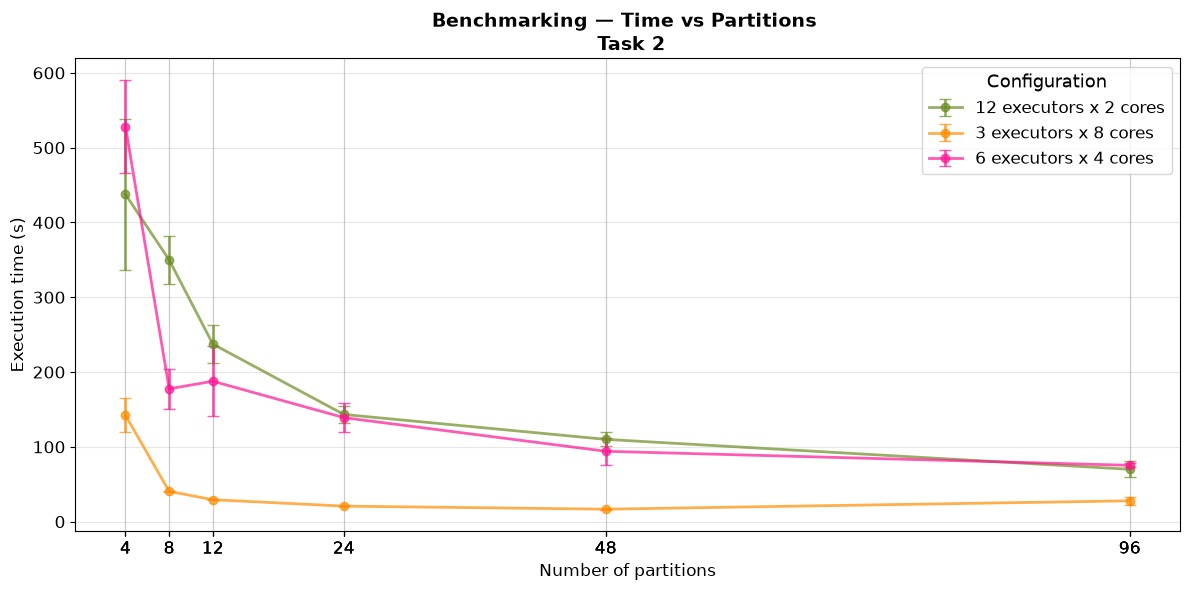

In [28]:
df1 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task2_12_2.csv")
df2 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task2_3_8.csv")
df3 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task2_6_4.csv")

# combine
df_all = pd.concat([df1, df2, df3], ignore_index=True)

# drop the first repetition (cold-start outlier)
df_clean = df_all[df_all['run_id'] != 1]

# average, std, and SEM over the remaining 4 repeats
df_avg = (
    df_clean
    .groupby(['num_executors', 'cores_per_executor', 'num_partitions'])['time_sec']
    .agg(mean_time='mean', std_time='std', n='count')
    .reset_index()
)
df_avg['sem_time'] = df_avg['std_time'] / np.sqrt(df_avg['n'])

configs = [(12, 2), (3, 8), (6, 4)]
colors = [ 'olivedrab','darkorange' ,'deeppink']
labels = ['12 executors x 2 cores', '3 executors x 8 cores', '6 executors x 4 cores']

plt.figure(figsize=(12, 6))
for (n_ex, n_c), color, label in zip(configs, colors, labels):
    subset = df_avg[
        (df_avg['num_executors'] == n_ex) &
        (df_avg['cores_per_executor'] == n_c)
    ].sort_values('num_partitions')
    plt.errorbar(subset['num_partitions'], subset['mean_time'],
                 yerr=subset['sem_time'],
                 marker='o', color=color, alpha = 0.7, label=label,
                 linewidth=2, capsize=4)
plt.xticks(df_avg['num_partitions'], fontsize = 12)
plt.yticks(fontsize=12)
plt.xlabel('Number of partitions', fontsize = 12)
plt.ylabel('Execution time (s)', fontsize = 12)
plt.title('Benchmarking — Time vs Partitions \n Task 2', fontsize = 14, fontweight = 'bold')
plt.legend(title='Configuration', fontsize = 12, title_fontsize = 13)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/mnt/vol2/.cache/kagglehub/benchmarking_csv/plots/benchmark_plot_task2.png', dpi=150)
plt.show()

In [38]:
spark.stop()